# Automobile (small regression dataset)

UCI Automobile: 205 cars, 25 features, target `price`, metric MSE.
Steps 1-3: learning curves for linear and quadratic regression, then cross-validation.

In [1]:
import sys
sys.path.append("..")

import pandas as pd
from IPython.display import display

from lab import FIGURES_DIR, RESULTS_DIR
from lab.experiment import baseline_score, cross_validate_models, run_learning_curve, summarize
from lab.models import make_model
from lab.plotting import plot_learning_curve
from lab.sampler import linear_sizes, log_sizes, sample_training_sets

RESULTS_DIR.mkdir(exist_ok=True)
pd.set_option("display.float_format", "{:.4g}".format)

In [2]:
DATASET = "automobile"
TASK = "regression"
KINDS = ["linear", "quadratic"]
N_REPEATS = 10   # samples per size

## Data
`?` is read as missing, the 4 cars without a price are dropped and `num-of-doors` /
`num-of-cylinders` are converted to numbers. Other missing values are imputed inside the
model pipeline.

In [3]:
from lab.data_automobile import load_automobile

X, y = load_automobile()
print(X.shape)
display(X.head())
print("missing values per column:")
print(X.isna().sum()[X.isna().sum() > 0])

(201, 25)


,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg
0,3,NaN,alfa-romero,gas,std,2,convertible,rwd,front,88.6,...,4,130,mpfi,3.47,2.68,9,111,5000,21,27
1,3,NaN,alfa-romero,gas,std,2,convertible,rwd,front,88.6,...,4,130,mpfi,3.47,2.68,9,111,5000,21,27
2,1,NaN,alfa-romero,gas,std,2,hatchback,rwd,front,94.5,...,6,152,mpfi,2.68,3.47,9,154,5000,19,26
3,2,164,audi,gas,std,4,sedan,fwd,front,99.8,...,4,109,mpfi,3.19,3.4,10,102,5500,24,30
4,2,164,audi,gas,std,4,sedan,4wd,front,99.4,...,5,136,mpfi,3.19,3.4,8,115,5500,18,22


missing values per column:
normalized-losses    37
num-of-doors          2
bore                  4
stroke                4
horsepower            2
peak-rpm              2
dtype: int64


## Train / validation split
Random 80/20, stratified on price quintiles. Prices are skewed (most cars $7-17k, a few
$30-45k) and MSE squares the errors, so with ~40 validation cars the score would depend a lot
on how many expensive cars end up there.

Caveat: the data contain several trims of the same model (almost identical rows), so a random
split is slightly optimistic.

In [4]:
from lab.data_automobile import split_automobile

X_train, X_val, y_train, y_val = split_automobile(X, y)
print(f"training part: {len(X_train)} rows, validation: {len(X_val)} rows")
display(pd.DataFrame({"train": y_train.describe(), "validation": y_val.describe()}).round(0))

training part: 160 rows, validation: 41 rows


,train,validation
count,160,41
mean,1.329e+04,1.288e+04
std,8062,7567
min,5118,5348
25%,7785,7609
50%,1.047e+04,9298
75%,1.651e+04,1.558e+04
max,4.54e+04,3.418e+04


In [5]:
# number of features after one-hot / squaring
for kind in KINDS:
    prep = make_model(kind).named_steps["prep"].fit(X_train)
    print(f"{kind:>20}: {prep.transform(X_train.iloc[:5]).shape[1]} features")

              linear: 67 features
           quadratic: 220 features


The number of features p is larger than most (linear) or all (quadratic) training sizes n.
Only numeric columns are squared for the quadratic model.

## Steps 1 and 2: learning curves

In [6]:
# 10, 20, ..., whole training part
sizes = linear_sizes(10, len(X_train), 10)
if sizes[-1] != len(X_train):
    sizes.append(len(X_train))
print(sizes)

samples = sample_training_sets(y_train, sizes, N_REPEATS, TASK)
curve = run_learning_curve(X_train, y_train, X_val, y_val, KINDS, samples, TASK, verbose=False)
curve.to_csv(RESULTS_DIR / f"{DATASET}_curve.csv", index=False)

stats = summarize(curve)
display(stats)

[10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120, 130, 140, 150, 160]


model size train_score                                          \
                          mean       std    median       q25       q75   
0      linear   10    7.74e-23 8.735e-23 5.414e-23 2.695e-23 8.199e-23   
1      linear   20   6.857e-21 2.062e-20 1.005e-22 4.905e-23 1.868e-22   
2      linear   30       604.7      1912 1.178e-22 7.925e-23 2.086e-22   
3      linear   40    2.27e+04 4.526e+04       785 5.157e-22 2.982e+04   
4      linear   50   7.995e+04 8.877e+04 6.907e+04      4997 1.203e+05   
5      linear   60    3.49e+05 1.772e+05 3.438e+05 1.963e+05 4.934e+05   
6      linear   70   6.999e+05 2.807e+05  5.55e+05 5.145e+05 8.957e+05   
7      linear   80   8.198e+05 4.485e+05 6.189e+05 5.474e+05 8.791e+05   
8      linear   90   1.516e+06 4.694e+05 1.521e+06 1.163e+06 1.724e+06   
9      linear  100   1.365e+06  3.79e+05 1.261e+06 1.167e+06 1.517e+06   
10     linear  110   1.776e+06 3.216e+05   1.8e+06 1.574e+06 1.902e+06   
11     linear  120   1.736e+06 3.162e+05 1.751e+06 1.593e+06  1.95e+06   
12     linear  130   1.762e+06 3.926e+05 1.795e+06 1.569e+06 1.933e+06   
13     linear  140   1.989e+06 3.776e+05 2.167e+06  1.79e+06 2.204e+06   
14     linear  150    2.23e+06 2.049e+05  2.31e+06 2.148e+06 2.385e+06   
15     linear  160   2.324e+06         0 2.324e+06 2.324e+06 2.324e+06   
16  quadratic   10    9.44e-23 1.054e-22 6.303e-23 3.313e-23 8.735e-23   
17  quadratic   20   1.384e-21 3.935e-21 1.343e-22 8.125e-23 2.306e-22   
18  quadratic   30   1.262e-22 1.082e-22 9.354e-23 7.212e-23 1.036e-22   
19  quadratic   40        4841 1.217e+04 4.923e-22 1.913e-22 1.437e-20   
20  quadratic   50        4975      9874 5.673e-21 5.935e-22      6075   
21  quadratic   60        9250 1.168e+04      3375 1.717e-21 2.144e+04   
22  quadratic   70        9086 1.274e+04      2893 1.186e-19 1.785e+04   
23  quadratic   80        4305      6030      2531 1.097e-19      6434   
24  quadratic   90        6590      7646      5312 2.624e-18      9500   
25  quadratic  100        7256      8589      4781      4050      5513   
26  quadratic  110        8912      7342      5847      4014 1.428e+04   
27  quadratic  120   1.459e+04      6210 1.674e+04 1.232e+04 1.848e+04   
28  quadratic  130   1.752e+04      5817 1.839e+04 1.626e+04 2.021e+04   
29  quadratic  140   1.936e+04      5186  1.98e+04 1.823e+04 2.297e+04   
30  quadratic  150   2.026e+04      4229 2.172e+04 1.921e+04 2.255e+04   
31  quadratic  160     2.3e+04         0   2.3e+04   2.3e+04   2.3e+04   

   val_score                                          
        mean       std    median       q25       q75  
0  4.376e+07 4.196e+07 3.068e+07 2.376e+07 4.661e+07  
1  2.681e+08 6.299e+08 2.453e+07  1.93e+07 3.526e+07  
2  6.539e+07 9.775e+07 3.237e+07 1.897e+07 5.456e+07  
3  1.743e+08 2.449e+08 7.296e+07 3.923e+07 1.299e+08  
4  1.632e+09 3.413e+09 4.472e+08 1.575e+08 1.164e+09  
5  5.126e+07 3.483e+07 3.904e+07 3.188e+07 5.557e+07  
6  6.777e+07 9.768e+07 3.331e+07 1.523e+07 3.918e+07  
7  2.585e+07 1.382e+07 2.466e+07 1.619e+07 3.636e+07  
8  1.469e+07 1.228e+07 1.007e+07 8.876e+06 1.431e+07  
9  1.164e+07 7.472e+06 1.126e+07 4.547e+06 1.558e+07  
10 7.171e+06 4.058e+06 5.714e+06 4.212e+06 7.917e+06  
11 8.125e+06 6.827e+06  5.73e+06 4.283e+06 8.624e+06  
12 4.138e+06 1.119e+06 3.762e+06 3.539e+06 4.614e+06  
13 4.286e+06 6.668e+05 4.033e+06 3.882e+06 4.915e+06  
14 3.848e+06 3.647e+05 3.828e+06 3.593e+06 3.898e+06  
15 3.581e+06         0 3.581e+06 3.581e+06 3.581e+06  
16 4.793e+07 3.947e+07 3.223e+07 2.333e+07 5.076e+07  
17 4.469e+08 1.213e+09 2.653e+07 1.982e+07 3.875e+07  
18 4.399e+07 5.031e+07 2.104e+07 1.943e+07 4.171e+07  
19 4.701e+08 1.232e+09   2.3e+07 1.969e+07 1.294e+08  
20 9.392e+08 1.496e+09 9.105e+07 4.877e+07 1.417e+09  
21 3.106e+08 4.111e+08 1.346e+08 7.101e+07 3.205e+08  
22 1.716e+10  4.99e+10 6.273e+08 1.588e+08 2.194e+09  
23 6.408e+09 1.411e+10 1.646e+09 6.818e+08  3.62e+09  
24  1.58e+10 2.296e+10 2.343e+09 1.158e+09 3.445e+10  
25 4.3

baseline validation MSE: 5.604e+07  (RMSE $7,486)


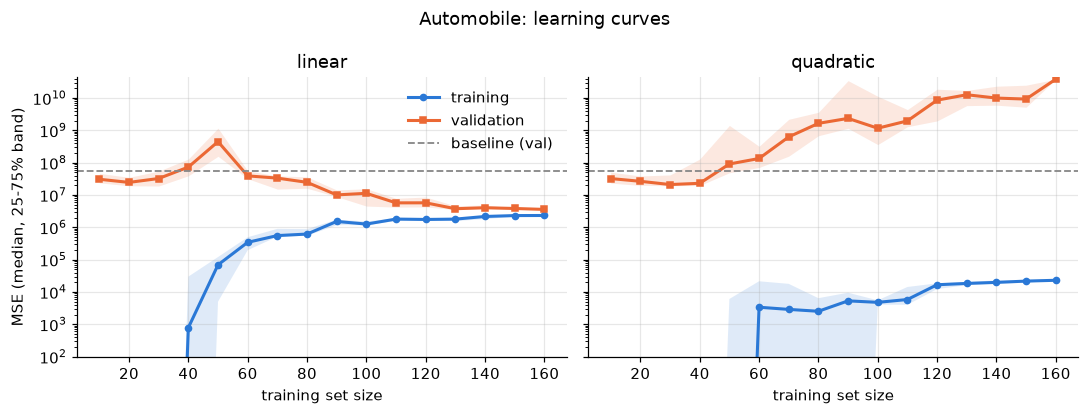

In [7]:
# baseline: predict the training mean
baseline = baseline_score(X_train, y_train, X_val, y_val, TASK)
print(f"baseline validation MSE: {baseline:.4g}  (RMSE ${baseline ** 0.5:,.0f})")

# training MSE 0 for small n is cut off by ylim on the log axis
fig = plot_learning_curve(curve, "MSE", "Automobile: learning curves", baseline=baseline,
                          log_y=True, ylim=(1e2, None),
                          path=FIGURES_DIR / f"{DATASET}_learning_curves.png")

### Explanation (1d)

**Training error.** For small n the training MSE is 0: with at least as many features as
points, least squares fits every point exactly. Once n exceeds the number of effectively
independent features (fewer than p: makes missing from the sample give all-zero columns, and
some columns are near-duplicates, e.g. city/highway mpg) it rises and levels off at the
bias + noise level.

**Validation error.** High for small n and worst around n ≈ p (here n = 50), where the system
is almost singular and the coefficients become huge. With more data it drops towards the
training error; the remaining gap is variance.

**Quadratic.** 220 features for at most 160 cars, so it never leaves the p > n regime: the
training MSE stays near 0 and the validation MSE gets worse as n approaches p.

The bands (25-75% over the repeats) are wide for small n and vanish at the full size, where
every repeat uses the same rows.

## Step 3: cross-validation
5-fold CV on the training part (each fold trains on ~128 cars).

In [8]:
cv = cross_validate_models(X_train, y_train, KINDS, TASK, k=5)
cv.to_csv(RESULTS_DIR / f"{DATASET}_cv.csv", index=False)

largest = stats[stats["size"] == stats["size"].max()]
curve_end = pd.DataFrame({
    "model": largest["model"],
    "curve_train": largest[("train_score", "median")],
    "curve_val": largest[("val_score", "median")],
})
comparison = cv.merge(curve_end, on="model")
display(comparison)
print("CV chooses:", cv.loc[cv["cv_mean"].idxmin(), "model"])

,model,cv_mean,cv_std,n_rows,curve_train,curve_val
0,linear,1.528e+07,1.212e+07,160,2.324e+06,3.581e+06
1,quadratic,1.084e+10,1.115e+10,160,2.3e+04,3.815e+10


CV chooses: linear


### CV vs. learning curves

CV picks the **linear** model, same as the validation curves.

- The CV error is far above the training error at full size (the training error is measured on
  the points the model was fitted on).
- CV and validation error are of the same order but not equal: with ~30-40 held-out cars the
  result depends a lot on which cars are held out (`cv_std` is close to `cv_mean`). Our
  validation set has no car above ~$34k. CV averages over 5 folds, each trained on ~128
  instead of 160 cars.
- For the quadratic model the CV error is huge and unstable, as in the curves.